#### Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

from sentence_transformers import SentenceTransformer, util
from sklearn.metrics.pairwise import cosine_similarity

import warnings
warnings.filterwarnings("ignore")

#### Reading our dataset

In [2]:
df = pd.read_csv("ai-layoffs-register.csv")
df.head()

,Company,Date,Sector,Country,Functions,Roles counted,Roles reported (not counted),Why not counted,% of workforce,Evidence tier,Attribution,Execution,Counts in US index,Claim,Source,Source URL,Event ID,Kind,What the employer said,Job families
0,Barclays,2026-10-22,Banking,United Kingdom,"Support functions, including software develope...",5000.0,NaN,NaN,about 5% of employees (Barclays' own figure; t...,Tier 1,mixed,partial,no,Barclays' Q3 2026 results presentation (22 Oct...,Barclays: Q3 2026 Results Presentation,https://home.barclays/content/dam/home-barclay...,barclays-2026-10,cut,Cited AI among other reasons,Corporate functions; Software engineering and IT
1,National Australia Bank,2026-10-20,Banking,Australia,Corporate functions (per NAB); Senior manageme...,NaN,2500.0,The company said the cut was not caused by AI;...,up to about 6% of its internal workforce (NAB),Tier 1,blamed,announced,no,"The Nightly (October 20, 2026): ""Kyle Rodda, a...",NAB (ASX announcement): NAB simplifying operat...,https://www.nab.com.au/news/nab-updates/nab-si...,national-australia-bank-2026-10,cut,Denied the AI link others made,Corporate functions; Management layers; Operat...
2,Vermont Information Processing,2026-10-20,Beverage industry software,United States,Not specified,NaN,NaN,NaN,NaN,Tier 2,blamed,executed,no,"Seven Days (October 20, 2026): ""The move appea...",Seven Days: A Colchester Tech Firm Has Been Le...,https://www.sevendaysvt.com/news/a-colchester-...,vermont-information-processing-2026-10,cut,Named no AI reason; others linked it to AI,Not specified
3,HDFC Bank,2026-10-17,Banking,India,No roles cut (a projection: fewer people in ba...,NaN,NaN,NaN,NaN,Tier 1,mixed,announced,no,"Sashidhar Jagdishan, outgoing managing directo...",Investing.com: Earnings call transcript: HDFC ...,https://ng.investing.com/news/stock-market-new...,hdfc-bank-2026-10,workforce statement,Spoke about AI and headcount; no cut announced,Not specified
4,Lookiero,2026-10-16,Online personal styling (fashion e-commerce),Spain,Not specified (Gananzia's internal sources pla...,NaN,50.0,"The number was reported by the press, not stat...",about 10% of the group's staff (the company's ...,Tier 2,mixed,announced,no,"Lookiero Outfittery Group, in its official res...",Gananzia: Lookiero prepara un ERE pese a recib...,https://gananzia.com/lookiero-prepara-un-ere-p...,lookiero-2026-10,cut,Cited AI among other reasons,Not specified



| Column | Meaning |
| --- | --- |
| `Company` | Employer name as it appears in the source. |
| `Date` | Event date (ISO `YYYY-MM-DD`): the announcement, filing, or effective date. |
| `Sector` | The employer's sector. |
| `Country` | The employer's home country (headquarters or domicile), as free text; for a few events it names where the roles were instead, or notes that the employer is global. |
| `Functions` | The roles cut, where a source says which, as entries separated by "; " (no entry contains a semicolon). An entry that comes from reporting names the outlet ("per ..."); when no source says which roles went, the entry begins "Not specified". |
| `Roles counted` | Headcount that meets the register's standard for an AI-attributed cut and enters the worldwide totals. Blank when no qualifying figure exists. |
| `Roles reported (not counted)` | Headcount reported for the event that the register deliberately does not count. Kept separate so counted and reported facts are never conflated. |
| `Why not counted` | The grounds for setting that reported figure aside, in plain words: the company said the cut was not caused by AI, or it has not named AI as the cause; or the number is not a figure the company stated as a cut (reported by the press or given by a union rather than stated by the company, an upper limit, a net change in headcount, roles shed through attrition, or a count that includes contractors or roles moved to other teams or locations). |
| `% of workforce` | Share of the workforce affected, where the source expresses it. |
| `Evidence tier` | Strength of the evidence for the AI attribution. Tier 1 = primary filing or first-party company statement; Tier 2 = named, credible reporting; Tier 3 = weaker or single-source signal. |
| `Attribution` | How strongly the cut is tied to AI. `explicit` = the employer itself names AI as the cause; `mixed` = AI is one stated factor among others (efficiency, restructuring); `blamed` = a credible source names AI but the employer does not, so the row is never counted. |
| `Execution` | Status: `announced`, `executed`, `partial`, `reversed` or `unknown`. |
| `Counts in US index` | `yes` only when a counted figure covers US-based roles, so it enters the US index sum. `no` for every other row, including US-based rows whose figure is not counted. |
| `Claim` | A short, sourced description of exactly what was disclosed and how it is classified. |
| `Source` | The name of the source (for example, a specific Form 8-K or a named news report). |
| `Source URL` | A resolvable link to that source, free to open. |
| `Event ID` | The register's stable identifier for the event (for example `cisco-2024-08`), the same id the JSON API uses. Added in 1.35. |
| `Kind` | `cut` for a layoff or workforce reduction; `workforce statement` for an employer's public statement about AI and the size of its workforce made when no discrete cut was announced (a forecast, or a headcount said to have fallen through attrition). A statement never carries a counted figure; leave these rows out of any count of cuts. Added in 1.35. |
| `What the employer said` | The employer's own position on AI for this event, in one of seven fixed labels the site also shows: "Declared the cut AI-related", "Cited AI among other reasons", "Cited AI, but also said AI was not a reason", "Credited AI; reduced through attrition, not layoffs", "Denied the AI link others made", "Named no AI reason; others linked it to AI", "Spoke about AI and headcount; no cut announced". Added in 1.35. |
| `Job families` | The kinds of work cut, coded by the register from the roles its sources name, separated by "; ": Customer service and support, Operations and back office, Software engineering and IT, Corporate functions, Sales and marketing, Management layers, Product and design, Writing, editorial and translation, Content moderation, Frontline and manual work, Consulting and professional services, or Not specified when no source says which roles went. Added in 1.35. |


#### Exploring and Cleaning each and every column

In [3]:
df.head()

,Company,Date,Sector,Country,Functions,Roles counted,Roles reported (not counted),Why not counted,% of workforce,Evidence tier,Attribution,Execution,Counts in US index,Claim,Source,Source URL,Event ID,Kind,What the employer said,Job families
0,Barclays,2026-10-22,Banking,United Kingdom,"Support functions, including software develope...",5000.0,NaN,NaN,about 5% of employees (Barclays' own figure; t...,Tier 1,mixed,partial,no,Barclays' Q3 2026 results presentation (22 Oct...,Barclays: Q3 2026 Results Presentation,https://home.barclays/content/dam/home-barclay...,barclays-2026-10,cut,Cited AI among other reasons,Corporate functions; Software engineering and IT
1,National Australia Bank,2026-10-20,Banking,Australia,Corporate functions (per NAB); Senior manageme...,NaN,2500.0,The company said the cut was not caused by AI;...,up to about 6% of its internal workforce (NAB),Tier 1,blamed,announced,no,"The Nightly (October 20, 2026): ""Kyle Rodda, a...",NAB (ASX announcement): NAB simplifying operat...,https://www.nab.com.au/news/nab-updates/nab-si...,national-australia-bank-2026-10,cut,Denied the AI link others made,Corporate functions; Management layers; Operat...
2,Vermont Information Processing,2026-10-20,Beverage industry software,United States,Not specified,NaN,NaN,NaN,NaN,Tier 2,blamed,executed,no,"Seven Days (October 20, 2026): ""The move appea...",Seven Days: A Colchester Tech Firm Has Been Le...,https://www.sevendaysvt.com/news/a-colchester-...,vermont-information-processing-2026-10,cut,Named no AI reason; others linked it to AI,Not specified
3,HDFC Bank,2026-10-17,Banking,India,No roles cut (a projection: fewer people in ba...,NaN,NaN,NaN,NaN,Tier 1,mixed,announced,no,"Sashidhar Jagdishan, outgoing managing directo...",Investing.com: Earnings call transcript: HDFC ...,https://ng.investing.com/news/stock-market-new...,hdfc-bank-2026-10,workforce statement,Spoke about AI and headcount; no cut announced,Not specified
4,Lookiero,2026-10-16,Online personal styling (fashion e-commerce),Spain,Not specified (Gananzia's internal sources pla...,NaN,50.0,"The number was reported by the press, not stat...",about 10% of the group's staff (the company's ...,Tier 2,mixed,announced,no,"Lookiero Outfittery Group, in its official res...",Gananzia: Lookiero prepara un ERE pese a recib...,https://gananzia.com/lookiero-prepara-un-ere-p...,lookiero-2026-10,cut,Cited AI among other reasons,Not specified


**Company Column**

In [4]:
list_of_companies_impacted_by_ai_layoffs = df["Company"].unique().tolist()


print("List of Companies Impacted by AI Layoffs")
print()
print(list_of_companies_impacted_by_ai_layoffs)
print()
print()
print("Number of such companies : ", len(list_of_companies_impacted_by_ai_layoffs))

List of Companies Impacted by AI Layoffs

['Barclays', 'National Australia Bank', 'Vermont Information Processing', 'HDFC Bank', 'Lookiero', 'Anthropic', 'Bank of America', 'GSK', 'KLM', 'Kroger', 'One Zero', 'HoneyBook', 'HSBC', 'DNB', 'FICO (Fair Isaac)', 'HubSpot', 'CWT Italia (Carlson Wagonlit Travel)', 'Tamedia', 'F-Secure', 'BMW', 'Cariad (Volkswagen)', 'Future plc', 'Disney', 'Thinkific', 'Sunrise', 'Worldia', 'Reach plc', 'Ouest-France', 'Wells Fargo', 'Oracle', 'Konecta', 'Commerce.com (BigCommerce)', 'IONOS', 'Booksy', 'McClatchy', 'Axis Bank', 'The Bancorp', 'Uber', 'Zscaler, Inc.', 'WPP', 'Zomato', 'Cubic3', 'PagerDuty, Inc.', 'Apple', 'Pentera', 'Rapid7', 'VideoAmp', 'LegalZoom', 'TikTok', 'Sparkgeo', 'E.W. Scripps', 'Latch, Inc. (DOOR)', 'Chime', 'Visa Inc.', 'Commonwealth Bank', 'Papaya Gaming', 'Patreon', 'monday.com', 'Amazon', 'CDW Corporation', 'Sprout Social, Inc.', 'Freight Technologies (Fr8Tech)', 'JPMorgan Chase', 'Thomson Reuters Corporation', 'GoKwik', 'Bragg G

Checking for null values

In [5]:
df["Company"].isna().sum()

np.int64(0)

**Converting the date column to pandas datetime format**

In [6]:
df["Date"] = pd.to_datetime(df["Date"])

**Sector Column**

In [7]:
df.head()

,Company,Date,Sector,Country,Functions,Roles counted,Roles reported (not counted),Why not counted,% of workforce,Evidence tier,Attribution,Execution,Counts in US index,Claim,Source,Source URL,Event ID,Kind,What the employer said,Job families
0,Barclays,2026-10-22,Banking,United Kingdom,"Support functions, including software develope...",5000.0,NaN,NaN,about 5% of employees (Barclays' own figure; t...,Tier 1,mixed,partial,no,Barclays' Q3 2026 results presentation (22 Oct...,Barclays: Q3 2026 Results Presentation,https://home.barclays/content/dam/home-barclay...,barclays-2026-10,cut,Cited AI among other reasons,Corporate functions; Software engineering and IT
1,National Australia Bank,2026-10-20,Banking,Australia,Corporate functions (per NAB); Senior manageme...,NaN,2500.0,The company said the cut was not caused by AI;...,up to about 6% of its internal workforce (NAB),Tier 1,blamed,announced,no,"The Nightly (October 20, 2026): ""Kyle Rodda, a...",NAB (ASX announcement): NAB simplifying operat...,https://www.nab.com.au/news/nab-updates/nab-si...,national-australia-bank-2026-10,cut,Denied the AI link others made,Corporate functions; Management layers; Operat...
2,Vermont Information Processing,2026-10-20,Beverage industry software,United States,Not specified,NaN,NaN,NaN,NaN,Tier 2,blamed,executed,no,"Seven Days (October 20, 2026): ""The move appea...",Seven Days: A Colchester Tech Firm Has Been Le...,https://www.sevendaysvt.com/news/a-colchester-...,vermont-information-processing-2026-10,cut,Named no AI reason; others linked it to AI,Not specified
3,HDFC Bank,2026-10-17,Banking,India,No roles cut (a projection: fewer people in ba...,NaN,NaN,NaN,NaN,Tier 1,mixed,announced,no,"Sashidhar Jagdishan, outgoing managing directo...",Investing.com: Earnings call transcript: HDFC ...,https://ng.investing.com/news/stock-market-new...,hdfc-bank-2026-10,workforce statement,Spoke about AI and headcount; no cut announced,Not specified
4,Lookiero,2026-10-16,Online personal styling (fashion e-commerce),Spain,Not specified (Gananzia's internal sources pla...,NaN,50.0,"The number was reported by the press, not stat...",about 10% of the group's staff (the company's ...,Tier 2,mixed,announced,no,"Lookiero Outfittery Group, in its official res...",Gananzia: Lookiero prepara un ERE pese a recib...,https://gananzia.com/lookiero-prepara-un-ere-p...,lookiero-2026-10,cut,Cited AI among other reasons,Not specified


In [8]:
industry_groups = {
    "Finance": [
        "Banking",
        "Digital banking",
        "Banking (wealth management)",
        "Banking (fintech partner bank)",
        "Fintech / consumer banking app",
        "Payments / Fintech",
        "Financial services / Banking",
        "Financial services / Digital banking",
        "Fintech (payments)",
        "Fintech / Payments (AP/AR automation)",
        "Fintech / Payments",
        "Crypto / Fintech",
        "Crypto / fintech",
        "Cryptocurrency exchange (fintech)",
        "Crypto exchange",
        "crypto exchange",
        "digital asset custody and infrastructure",
        "Fintech",
        "Fintech (neobanking)",
        "Fintech (custody for investment advisers)",
        "Fintech (digital payments)",
        "Fintech / digital payments",
        "Fintech / customer service",
        "E-commerce / fintech",
        "Insurance Brokerage / Fintech",
        "Insurance brokerage and fintech",
        "Insurance",
        "Insurance (digital insurer)",
        "Insurance / Travel",
        "Banking / financial services",
        "Wealth-management software (fintech)",
        "Bitcoin mining / digital infrastructure",
        "Fintech / payments (one-click checkout)"
    ],

    "Software": [
        "Beverage industry software",
        "Small-business management software",
        "Software (CRM and marketing platform)",
        "Automotive software",
        "Online course software",
        "E-commerce software",
        "Appointment booking software (beauty and wellness)",
        "Software (incident management / DevOps SaaS)",
        "Software / Work management",
        "Software / Social media management",
        "E-commerce enablement / SaaS",
        "Hospitality Software (hotel property-management SaaS)",
        "Legal technology",
        "Website-building software (WordPress)",
        "Customer data software",
        "Software / Search & observability",
        "Enterprise SaaS (IT workflow software)",
        "Dev Tools",
        "Marketing technology",
        "Website Builder / SaaS",
        "Website-building software (SaaS)",
        "Productivity software (SaaS)",
        "Business software (SaaS)",
        "IT management software for managed service providers",
        "Music licensing and creative software",
        "Product-management software (SaaS)",
        "Software (product analytics)",
        "data observability software",
        "Cloud data software",
        "Data infrastructure software (cloud data warehouse)",
        "Enterprise SaaS (CRM)",
        "Enterprise SaaS (developer/collaboration software)",
        "Software (Apple device management)",
        "Competitive intelligence software",
        "Enterprise information management software",
        "Contact-center software",
        "Design software",
        "Infrastructure engineering software",
        "Enterprise software (ERP)",
        "Software",
        "Enterprise software (digital adoption)",
        "HR software",
        "Conversational AI software",
        "AI language technology (translation software)",
        "AI translation software",
        "Technology (enterprise software/cloud)",
        "Technology (cloud / managed services)",
        "Big Tech / Cloud / Software",
        "Big Tech / Cloud",
        "Big Tech / E-commerce / Cloud",
        "Big Tech / Social / AI",
        "Technology services and software",
        "Technology / Services",
        "Enterprise networking / infrastructure software",
        "Internet Infrastructure",
        "Technology hardware (PCs and printers)",
        "Enterprise hardware / infrastructure",
        "Technology hardware (VR, metaverse and wearables hardware)",
        "Software / Cybersecurity",
        "Software / developer tools (open source)",
        "Web hosting and cloud services"
    ],

    "AI & Data": [
        "Artificial intelligence (AI models and software)",
        "Analytics software and credit scoring",
        "Technology (AI models)",
        "Advertising measurement software",
        "Geospatial data engineering services",
        "AI software for drug discovery",
        "Consumer apps / AI video models",
        "Creative technology (stock media and AI video tools)",
        "AI transcription and captioning",
        "Data analytics and digital operations services",
        "Audience measurement",
        "B2B sales data software",
        "crypto data and analytics"
    ],

    "Cybersecurity": [
        "Cybersecurity software",
        "Cybersecurity (SaaS)",
        "Cybersecurity (SaaS and managed services)",
        "Cybersecurity (managed detection and response / security operations)",
        "Cybersecurity (managed detection and response)",
        "Cybersecurity Software",
        "Data security and privacy software",
        "Software / Cybersecurity"
    ],

    "Media": [
        "Media (newspapers)",
        "Media and publishing",
        "News publishing",
        "Newspaper publishing",
        "Local newspapers",
        "Regional newspapers",
        "Broadcast media (local TV stations)",
        "Professional information / Media",
        "Media / Broadcasting",
        "Media/Journalism",
        "News Publishing",
        "Digital Media",
        "Digital media",
        "Business and trade media",
        "Public radio broadcasting",
        "Social media (US joint venture; office including content moderation)",
        "Social media (trust and safety, content moderation)",
        "Social media",
        "Consumer internet / social media",
        "Consumer internet (Dailyhunt, Josh)",
        "Creative digital-asset marketplace (Shutterstock subsidiary)",
        "Media monitoring and PR analytics"
    ],

    "Retail": [
        "Online personal styling (fashion e-commerce)",
        "Grocery retail",
        "Online luxury fashion retail",
        "Online travel / E-commerce",
        "E-commerce / Marketplace",
        "E-commerce (pan-African marketplace and logistics)",
        "Retail",
        "Online grocery technology and warehouse robotics",
        "Online fashion retail",
        "E-commerce / online resale",
        "E-commerce marketing software",
        "Online food delivery",
        "Consumer Goods / Tobacco",
        "Consumer Goods (CPG)",
        "Consumer goods (small household appliances)"
    ],

    "Telecom": [
        "Telecommunications",
        "Telecom",
        "Telecom software and IT services",
        "Telecom / BPO",
        "Business messaging software (CPaaS)",
        "Internet / Marketplace"
    ],

    "Travel": [
        "Airline",
        "Business travel management",
        "Travel (tailor-made tour operator)",
        "Technology / Ridesharing",
        "Connected-car software",
        "Hospitality software (short-term rental management)",
        "online travel agency",
        "Online travel",
        "Airlines / aviation group",
        "Maps and location technology",
        "geolocation and fraud-prevention software",
        "Automotive",
        "autonomous-vehicle testing software"
    ],

    "Logistics": [
        "Freight logistics software and brokerage",
        "Logistics software (SaaS)",
        "Logistics / Freight Brokerage",
        "Logistics",
        "E-commerce (pan-African marketplace and logistics)"
    ],

    "Healthcare": [
        "Pharmaceuticals and vaccines",
        "Healthcare / Revenue cycle",
        "Healthcare technology (SaaS)",
        "AI software for drug discovery",
        "AI drug-discovery software",
        "Healthcare",
        "Health tech (Alphabet)",
        "Pharmaceuticals",
        "Chemicals / Materials"
    ],

    "Education": [
        "Online course software",
        "tech career upskilling (edtech)",
        "Education / Software",
        "Online recruiting (early-career network)",
        "HR software",
        "HR / Payroll Software",
        "Online recruiting / HR technology (job search and employer reviews)",
        "Financial education (edtech)",
        "Education technology / academic integrity software",
        "Online creative courses (edtech)"
    ],

    "Consumer": [
        "Consumer technology",
        "Consumer Goods / Tobacco",
        "Consumer Goods (CPG)",
        "Consumer goods (small household appliances)",
        "Consumer software (family safety and location app)",
        "Online personal styling (fashion e-commerce)"
    ],

    "Gaming": [
        "Media and entertainment",
        "mobile games (skill-based competitions)",
        "Mobile games",
        "Gaming",
        "Video games",
        "Video game services (localisation, testing, audio)",
        "Live events ticketing",
        "Sports data (real-time data feeds for betting, fantasy and media)",
        "Creator membership platform",
        "iGaming / Online gambling technology",
        "gambling affiliate marketing and sports data"
    ],

    "IT Services": [
        "Contact centres and business process outsourcing (CRM/BPO)",
        "IT solutions / Value-added reseller",
        "IT services / BPO",
        "BPO / Call Centers",
        "IT services and consulting",
        "IT services / consulting",
        "IT services / enterprise tech",
        "Management consulting",
        "Advertising and marketing services",
        "Online freelance-work marketplace",
        "Technology services and software",
        "Telecom software and IT services",
        "Online legal services",
        "Legal"
    ],

    "Real Estate": [
        "Smart building / Property technology software",
        "Real estate technology (online home buying)",
        "Real estate software",
        "Real estate technology",
        "Home interiors (online platform)",
        "Online home-services marketplace"
    ]
}

In [9]:
industry_reverse_grouping = {}
for i in industry_groups:
    for j in industry_groups[i]:
        industry_reverse_grouping[j] = i.lower()
        industry_reverse_grouping[j.lower()] = i.lower()
    industry_reverse_grouping[i] = i.lower()
    industry_reverse_grouping[i.lower()] = i.lower()

df_1 = df.copy()
df_1["Sector"] = df_1["Sector"].str.lower().map(industry_reverse_grouping)

In [10]:
additional_sector_groups = {
    "Food delivery and quick commerce": "Retail",
    "marketing and customer-engagement software": "Software",
    "Blockchain and AI infrastructure startup (crypto)": "Finance",
    "Technology (VR, metaverse and wearables hardware)": "Software",
    "Mobile marketing measurement (ad tech)": "AI & Data",
    "Semiconductors": "Software",
    "Developer / Software": "Software"
}

for i in additional_sector_groups:
    industry_reverse_grouping[i] = additional_sector_groups[i].lower()
    industry_reverse_grouping[i.lower()] = additional_sector_groups[i].lower()

df_2 = df.copy()
df_2["Sector"] = df_2["Sector"].map(industry_reverse_grouping)

In [11]:
df_2["Sector"].value_counts()

Sector
software         84
finance          61
media            28
it services      20
telecom          17
education        16
travel           15
ai & data        14
retail           13
gaming           12
cybersecurity    11
healthcare       10
logistics         7
consumer          6
real estate       6
Name: count, dtype: int64

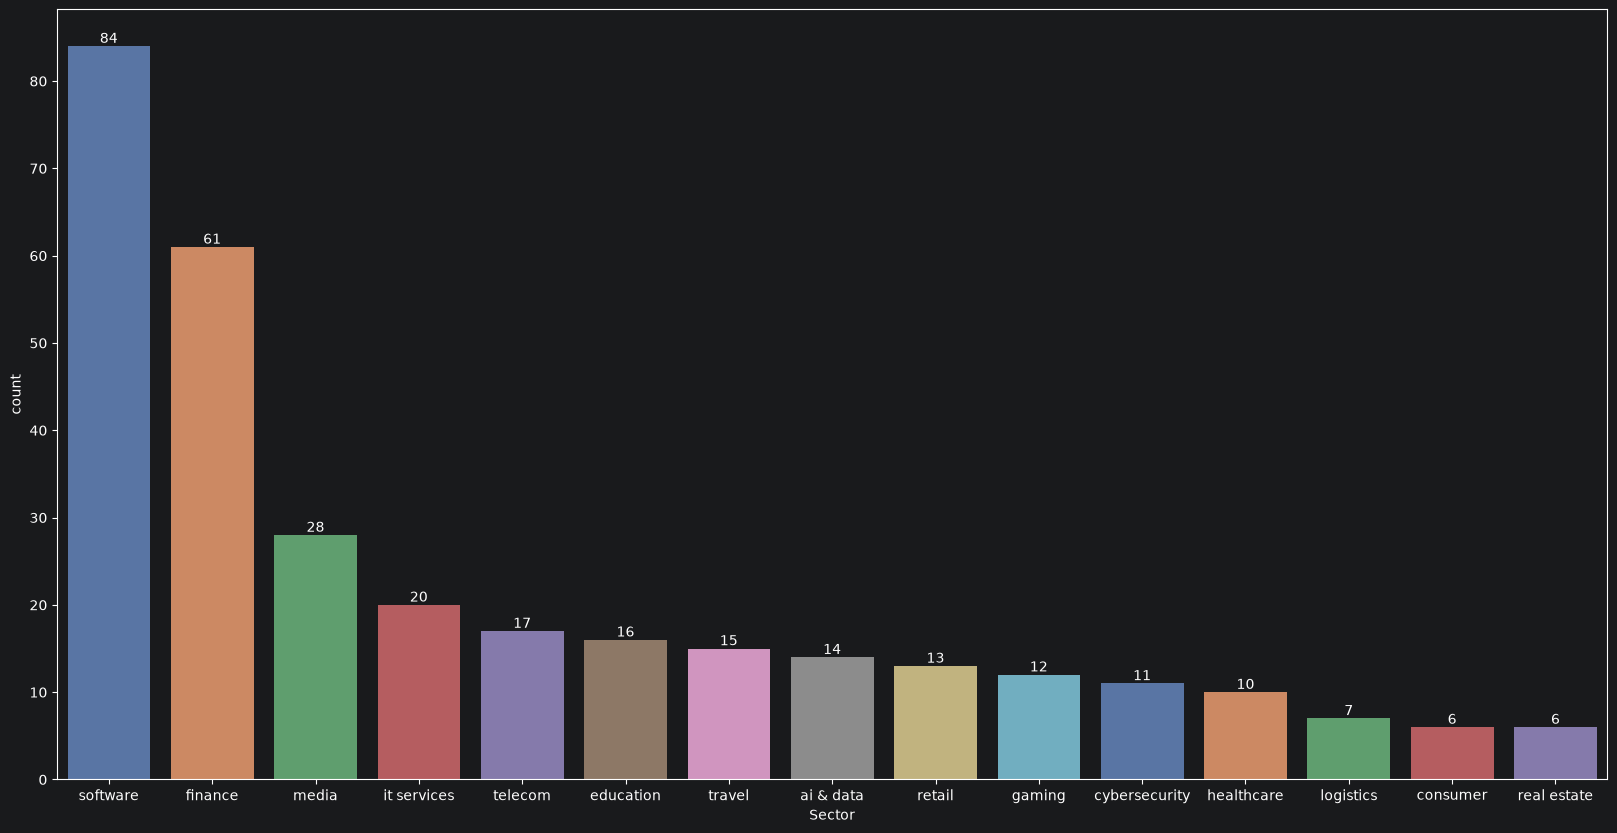

In [12]:
fig, ax = plt.subplots(figsize=(20, 10))
ax = sns.barplot(df_2["Sector"].value_counts(),palette="deep",ax=ax)
for i in ax.containers:
    ax.bar_label(i)

**Country**

In [13]:
df_3 = df_2.copy()
df_3["Country"] = df_3["Country"].str.split("(").str[0].str.strip()
df_3["Country"] = list(map(lambda x: x.split("/") if "/" in x else x,df_3["Country"]))
df_3["Country"] = list(map(lambda x: [i.strip() for i in x] if type(x)==list else x,df_3["Country"]))
df_3["Country"] = list(map(lambda x: x.replace(" and ",", ") if type(x)==str else x,df_3["Country"]))

df_3["Country"] = list(map(lambda x: x.split(",") if "," in x and type(x)==str else x,df_3["Country"]))
df_3["Country"] = list(map(lambda x: [i.strip() for i in x] if type(x)==list else x,df_3["Country"]))
df_3.at[286,"Country"] = df_3.loc[286,"Country"][0:2]

df_4 = df_3.copy()
df_4["Country"] = list(map(lambda x: "Global" if type(x)==list else x,df_4["Country"]))

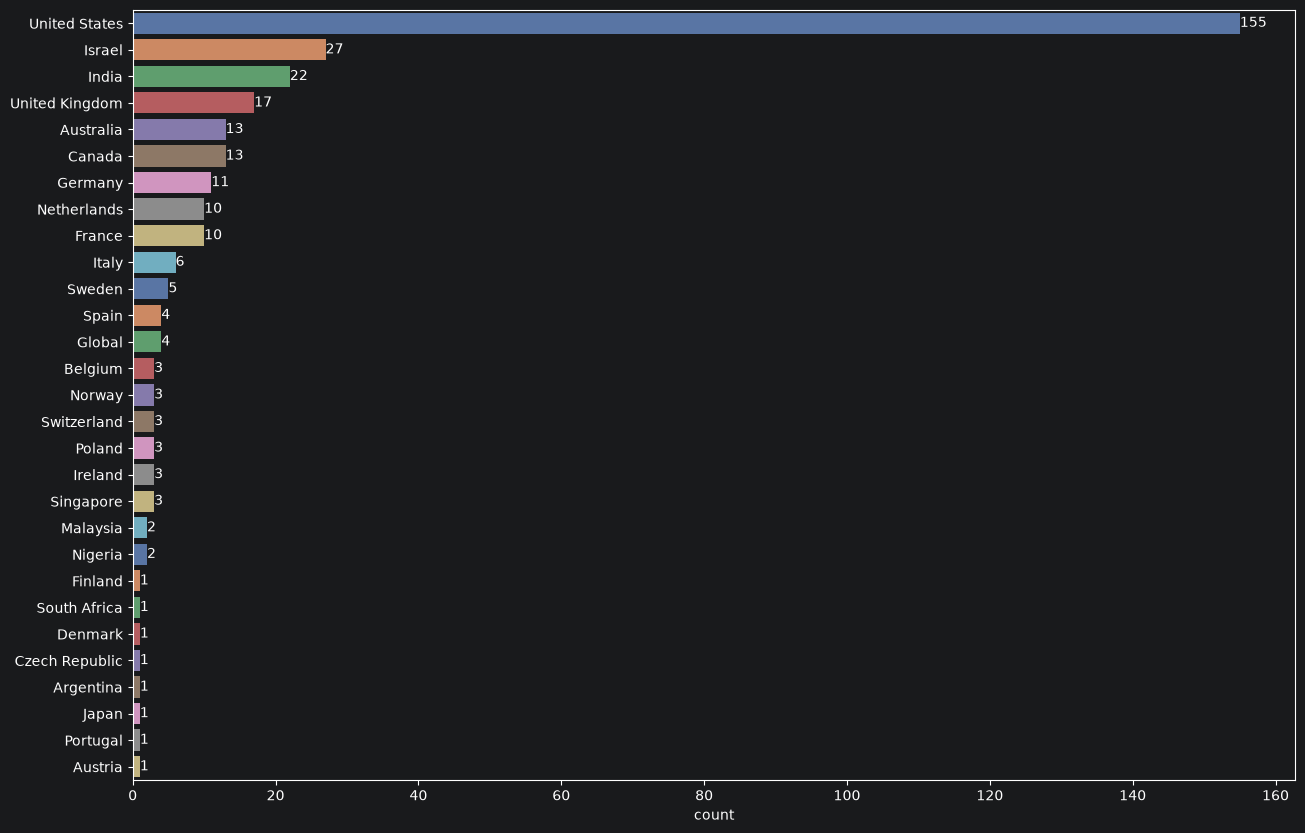

In [14]:
p = pd.Series()
ctr = 0
for i in df_3["Country"]:
    if type(i) == str:
        p[ctr] = i
    elif type(i) == list:
        for j in i:
            p[ctr] = j
            ctr += 1
    ctr += 1

fig, ax = plt.subplots(figsize=(15, 10))
ax = sns.barplot(p.value_counts(),palette="deep",ax=ax,orient="h")
for i in ax.containers:
    ax.bar_label(i)
#ax.tick_params(axis='x', rotation=45)

**Functions**

In [15]:
d4 = pd.read_csv("common-professions.csv")
d4["Date"] = pd.to_datetime(d4["Date"])

df_5 = pd.merge(left=df_4,right=d4,how="inner",on=["Company","Date"])
df_5.drop(columns=["Functions","Job families"],inplace=True)

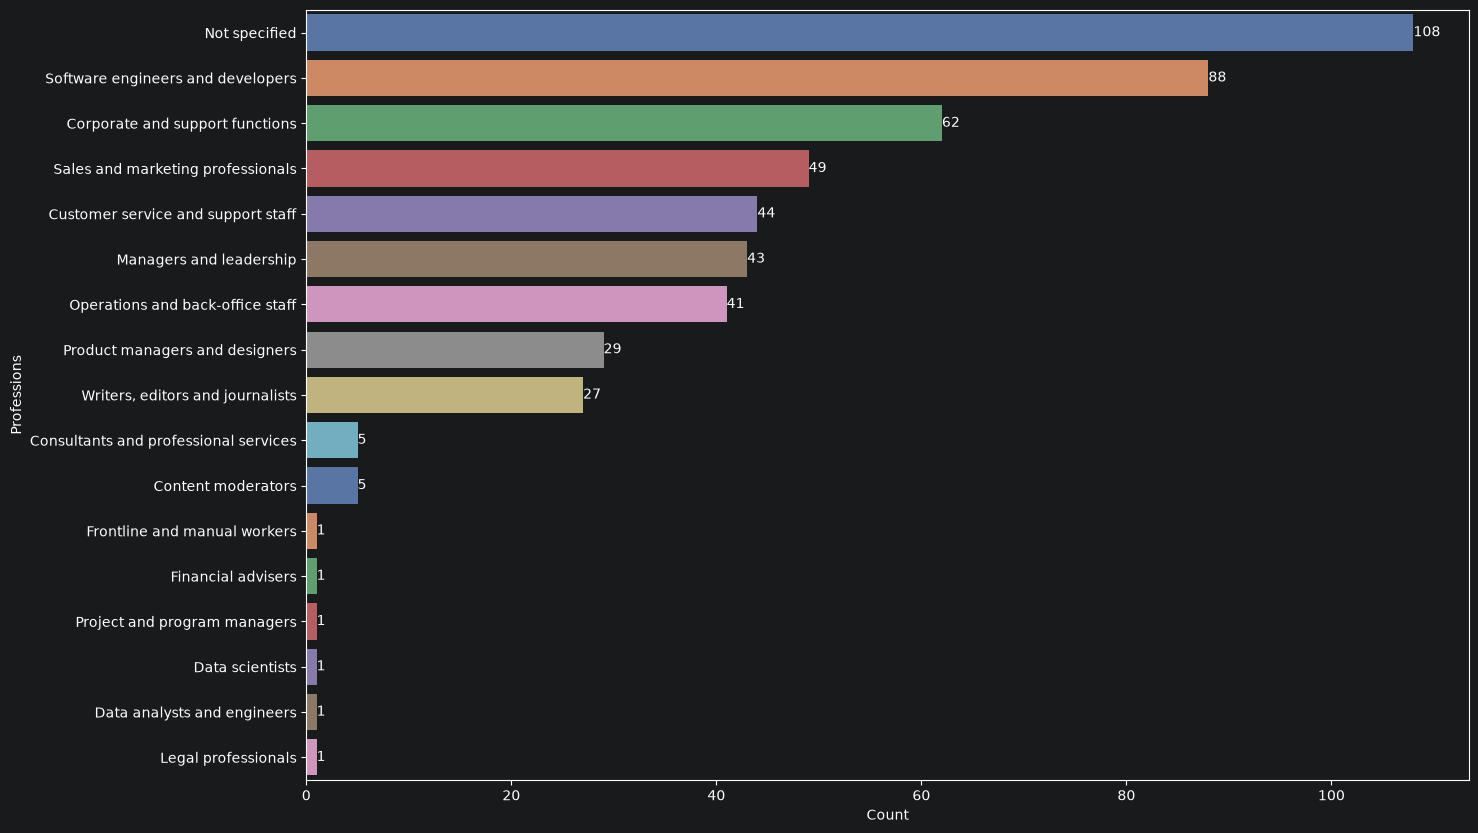

In [16]:
professions_split = df_5["Common professions"].str.split("; ")
o = []
for i in professions_split:
    o.extend(i)
professions_df = pd.DataFrame(np.unique(np.array(o),return_counts=True)).T
professions_df.columns = ["Professions","Count"]
professions_df.sort_values(by="Count",ascending=False,inplace=True)
fig,ax = plt.subplots(figsize=(15, 10))
ax = sns.barplot(y=professions_df["Professions"],x=professions_df["Count"],palette="deep",orient="h")
for i in ax.containers:
    ax.bar_label(i)
#ax.tick_params(axis='x', rotation=45)

**Roles counted, Roles reported (not counted), Why not counted, % of workforce**

In [17]:
print("Percentage of null values in counted rows               : ",(df_5["Roles counted"].isna().sum() * 100 / df_5.shape[0]).round(2))
print("Percentage of null values in rows that are not reported : ",(df_5["Roles reported (not counted)"].isna().sum() * 100 / df_5.shape[0]).round(2))
print("Percentage of null values why the row is not counted    : ",(df_5["Why not counted"].isna().sum() * 100 / df_5.shape[0]).round(2))
print("Percentage of null values in percentage of workforce    : ",(df_5["% of workforce"].isna().sum() * 100 / df_5.shape[0]).round(2))

Percentage of null values in counted rows               :  70.94
Percentage of null values in rows that are not reported :  48.75
Percentage of null values why the row is not counted    :  48.75
Percentage of null values in percentage of workforce    :  32.81


In [18]:
df_5

,Company,Date,Sector,Country,Roles counted,Roles reported (not counted),Why not counted,% of workforce,Evidence tier,Attribution,Execution,Counts in US index,Claim,Source,Source URL,Event ID,Kind,What the employer said,Common professions
0,Barclays,2026-10-22,finance,United Kingdom,5000.0,NaN,NaN,about 5% of employees (Barclays' own figure; t...,Tier 1,mixed,partial,no,Barclays' Q3 2026 results presentation (22 Oct...,Barclays: Q3 2026 Results Presentation,https://home.barclays/content/dam/home-barclay...,barclays-2026-10,cut,Cited AI among other reasons,Corporate and support functions; Software engi...
1,National Australia Bank,2026-10-20,finance,Australia,NaN,2500.0,The company said the cut was not caused by AI;...,up to about 6% of its internal workforce (NAB),Tier 1,blamed,announced,no,"The Nightly (October 20, 2026): ""Kyle Rodda, a...",NAB (ASX announcement): NAB simplifying operat...,https://www.nab.com.au/news/nab-updates/nab-si...,national-australia-bank-2026-10,cut,Denied the AI link others made,Corporate and support functions; Managers and ...
2,Vermont Information Processing,2026-10-20,software,United States,NaN,NaN,NaN,NaN,Tier 2,blamed,executed,no,"Seven Days (October 20, 2026): ""The move appea...",Seven Days: A Colchester Tech Firm Has Been Le...,https://www.sevendaysvt.com/news/a-colchester-...,vermont-information-processing-2026-10,cut,Named no AI reason; others linked it to AI,Not specified
3,HDFC Bank,2026-10-17,finance,India,NaN,NaN,NaN,NaN,Tier 1,mixed,announced,no,"Sashidhar Jagdishan, outgoing managing directo...",Investing.com: Earnings call transcript: HDFC ...,https://ng.investing.com/news/stock-market-new...,hdfc-bank-2026-10,workforce statement,Spoke about AI and headcount; no cut announced,Not specified
4,Lookiero,2026-10-16,consumer,Spain,NaN,50.0,"The number was reported by the press, not stat...",about 10% of the group's staff (the company's ...,Tier 2,mixed,announced,no,"Lookiero Outfittery Group, in its official res...",Gananzia: Lookiero prepara un ERE pese a recib...,https://gananzia.com/lookiero-prepara-un-ere-p...,lookiero-2026-10,cut,Cited AI among other reasons,Software engineers and developers; Product man...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315,BT Group,2023-05-18,telecom,United Kingdom,NaN,10000.0,"The number includes contractors, not only empl...","of 55,000 total cuts",Tier 1,mixed,announced,no,"BT said it would cut up to 55,000 jobs by 2030...",BT Group Newsroom (FY2023 results),https://newsroom.bt.com/results-for-the-full-y...,bt-group-2023-05,cut,Cited AI among other reasons,Customer service and support staff
316,IBM,2023-05-01,software,United States,NaN,7800.0,"The number was reported by the press, not stat...",~30% of back-office roles (projected),Tier 2,mixed,announced,no,CEO Arvind Krishna said he could 'easily see 3...,Bloomberg via The National (Krishna interview),https://www.thenationalnews.com/business/techn...,ibm-2023-2025,workforce statement,Spoke about AI and headcount; no cut announced,Operations and back-office staff; Corporate an...
317,Dropbox,2023-04-27,software,United States,500.0,NaN,NaN,about 16%,Tier 1,mixed,executed,no,"Dropbox CEO Drew Houston, letter to employees ...",Dropbox Blog: A message from our CEO (Drew Hou...,https://blog.dropbox.com/topics/company/a-mess...,dropbox-2023-04,cut,Cited AI among other reasons,Software engineers and developers; Sales and m...
318,Turnitin,2023-04-18,education,United States,NaN,NaN,NaN,NaN,Tier 1,explicit,announced,no,"Turnitin CEO Chris Caren, on the panel ""The Fu...",Global Silicon Valley (YouTube): The Future of...,https://www.youtube.com/watch?v=TDC1ceJbdPg&t=...,turnitin-2023-04,workforce statement,Spoke about AI and headcount; no cut announced,Not specified


In [19]:
df_5.to_csv("ai-layoffs-register-new.csv",index=False)

#### AI Layoffs Register – EDA roadmap

**1. Overall layoff statistics**
   - How are layoff events distributed over time?
   - Which companies have reported the highest number of layoffs?

**2. Industry analysis**
   - Which industries have experienced the highest layoff activity?
   - Which industries account for the largest number of affected employees?

**3. Geographical analysis**
   - Which countries have recorded the highest layoff activity?
   - How does AI attribution differ across countries?

**4. AI attribution analysis**
   - How are layoffs distributed across attribution categories?
   - Which industries have the highest proportion of explicit AI attribution?

**5. Workforce impact**
   - Which companies have reported the highest workforce reduction percentages?
   - How do announced and executed layoffs compare?

**6. Evidence quality**
   - How are layoff events distributed across evidence tiers?
   - Does evidence quality vary across AI attribution categories?

#### Exploratory Data Analysis

**1. Overall layoff statistics**

**How are layoff events distributed over time?**

In [20]:
df_5

,Company,Date,Sector,Country,Roles counted,Roles reported (not counted),Why not counted,% of workforce,Evidence tier,Attribution,Execution,Counts in US index,Claim,Source,Source URL,Event ID,Kind,What the employer said,Common professions
0,Barclays,2026-10-22,finance,United Kingdom,5000.0,NaN,NaN,about 5% of employees (Barclays' own figure; t...,Tier 1,mixed,partial,no,Barclays' Q3 2026 results presentation (22 Oct...,Barclays: Q3 2026 Results Presentation,https://home.barclays/content/dam/home-barclay...,barclays-2026-10,cut,Cited AI among other reasons,Corporate and support functions; Software engi...
1,National Australia Bank,2026-10-20,finance,Australia,NaN,2500.0,The company said the cut was not caused by AI;...,up to about 6% of its internal workforce (NAB),Tier 1,blamed,announced,no,"The Nightly (October 20, 2026): ""Kyle Rodda, a...",NAB (ASX announcement): NAB simplifying operat...,https://www.nab.com.au/news/nab-updates/nab-si...,national-australia-bank-2026-10,cut,Denied the AI link others made,Corporate and support functions; Managers and ...
2,Vermont Information Processing,2026-10-20,software,United States,NaN,NaN,NaN,NaN,Tier 2,blamed,executed,no,"Seven Days (October 20, 2026): ""The move appea...",Seven Days: A Colchester Tech Firm Has Been Le...,https://www.sevendaysvt.com/news/a-colchester-...,vermont-information-processing-2026-10,cut,Named no AI reason; others linked it to AI,Not specified
3,HDFC Bank,2026-10-17,finance,India,NaN,NaN,NaN,NaN,Tier 1,mixed,announced,no,"Sashidhar Jagdishan, outgoing managing directo...",Investing.com: Earnings call transcript: HDFC ...,https://ng.investing.com/news/stock-market-new...,hdfc-bank-2026-10,workforce statement,Spoke about AI and headcount; no cut announced,Not specified
4,Lookiero,2026-10-16,consumer,Spain,NaN,50.0,"The number was reported by the press, not stat...",about 10% of the group's staff (the company's ...,Tier 2,mixed,announced,no,"Lookiero Outfittery Group, in its official res...",Gananzia: Lookiero prepara un ERE pese a recib...,https://gananzia.com/lookiero-prepara-un-ere-p...,lookiero-2026-10,cut,Cited AI among other reasons,Software engineers and developers; Product man...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315,BT Group,2023-05-18,telecom,United Kingdom,NaN,10000.0,"The number includes contractors, not only empl...","of 55,000 total cuts",Tier 1,mixed,announced,no,"BT said it would cut up to 55,000 jobs by 2030...",BT Group Newsroom (FY2023 results),https://newsroom.bt.com/results-for-the-full-y...,bt-group-2023-05,cut,Cited AI among other reasons,Customer service and support staff
316,IBM,2023-05-01,software,United States,NaN,7800.0,"The number was reported by the press, not stat...",~30% of back-office roles (projected),Tier 2,mixed,announced,no,CEO Arvind Krishna said he could 'easily see 3...,Bloomberg via The National (Krishna interview),https://www.thenationalnews.com/business/techn...,ibm-2023-2025,workforce statement,Spoke about AI and headcount; no cut announced,Operations and back-office staff; Corporate an...
317,Dropbox,2023-04-27,software,United States,500.0,NaN,NaN,about 16%,Tier 1,mixed,executed,no,"Dropbox CEO Drew Houston, letter to employees ...",Dropbox Blog: A message from our CEO (Drew Hou...,https://blog.dropbox.com/topics/company/a-mess...,dropbox-2023-04,cut,Cited AI among other reasons,Software engineers and developers; Sales and m...
318,Turnitin,2023-04-18,education,United States,NaN,NaN,NaN,NaN,Tier 1,explicit,announced,no,"Turnitin CEO Chris Caren, on the panel ""The Fu...",Global Silicon Valley (YouTube): The Future of...,https://www.youtube.com/watch?v=TDC1ceJbdPg&t=...,turnitin-2023-04,workforce statement,Spoke about AI and headcount; no cut announced,Not specified


In [21]:
def layoff_events_distribution(df_5,**kwargs):
    df_e = df_5.copy()
    for i in kwargs:
        df_e = df_e[df_e[i].isin(kwargs[i])]

    da = df_e["Date"].value_counts().reset_index().sort_values(by="Date").reset_index(drop=True)
    da["Cumulative Count"] = np.cumsum(da["count"].values)

    fig, ax = plt.subplots(nrows=2,ncols=2,figsize=(20,15))
    sns.histplot(df_e["Date"],ax=ax[0,0])
    sns.kdeplot(df_e["Date"],ax=ax[0,1])
    sns.lineplot(da["Cumulative Count"],ax=ax[1,0])

    ax[0,0].tick_params(axis='x', rotation=45)
    ax[0,1].tick_params(axis='x', rotation=45)
    ax[1,0].tick_params(axis='x', rotation=45)

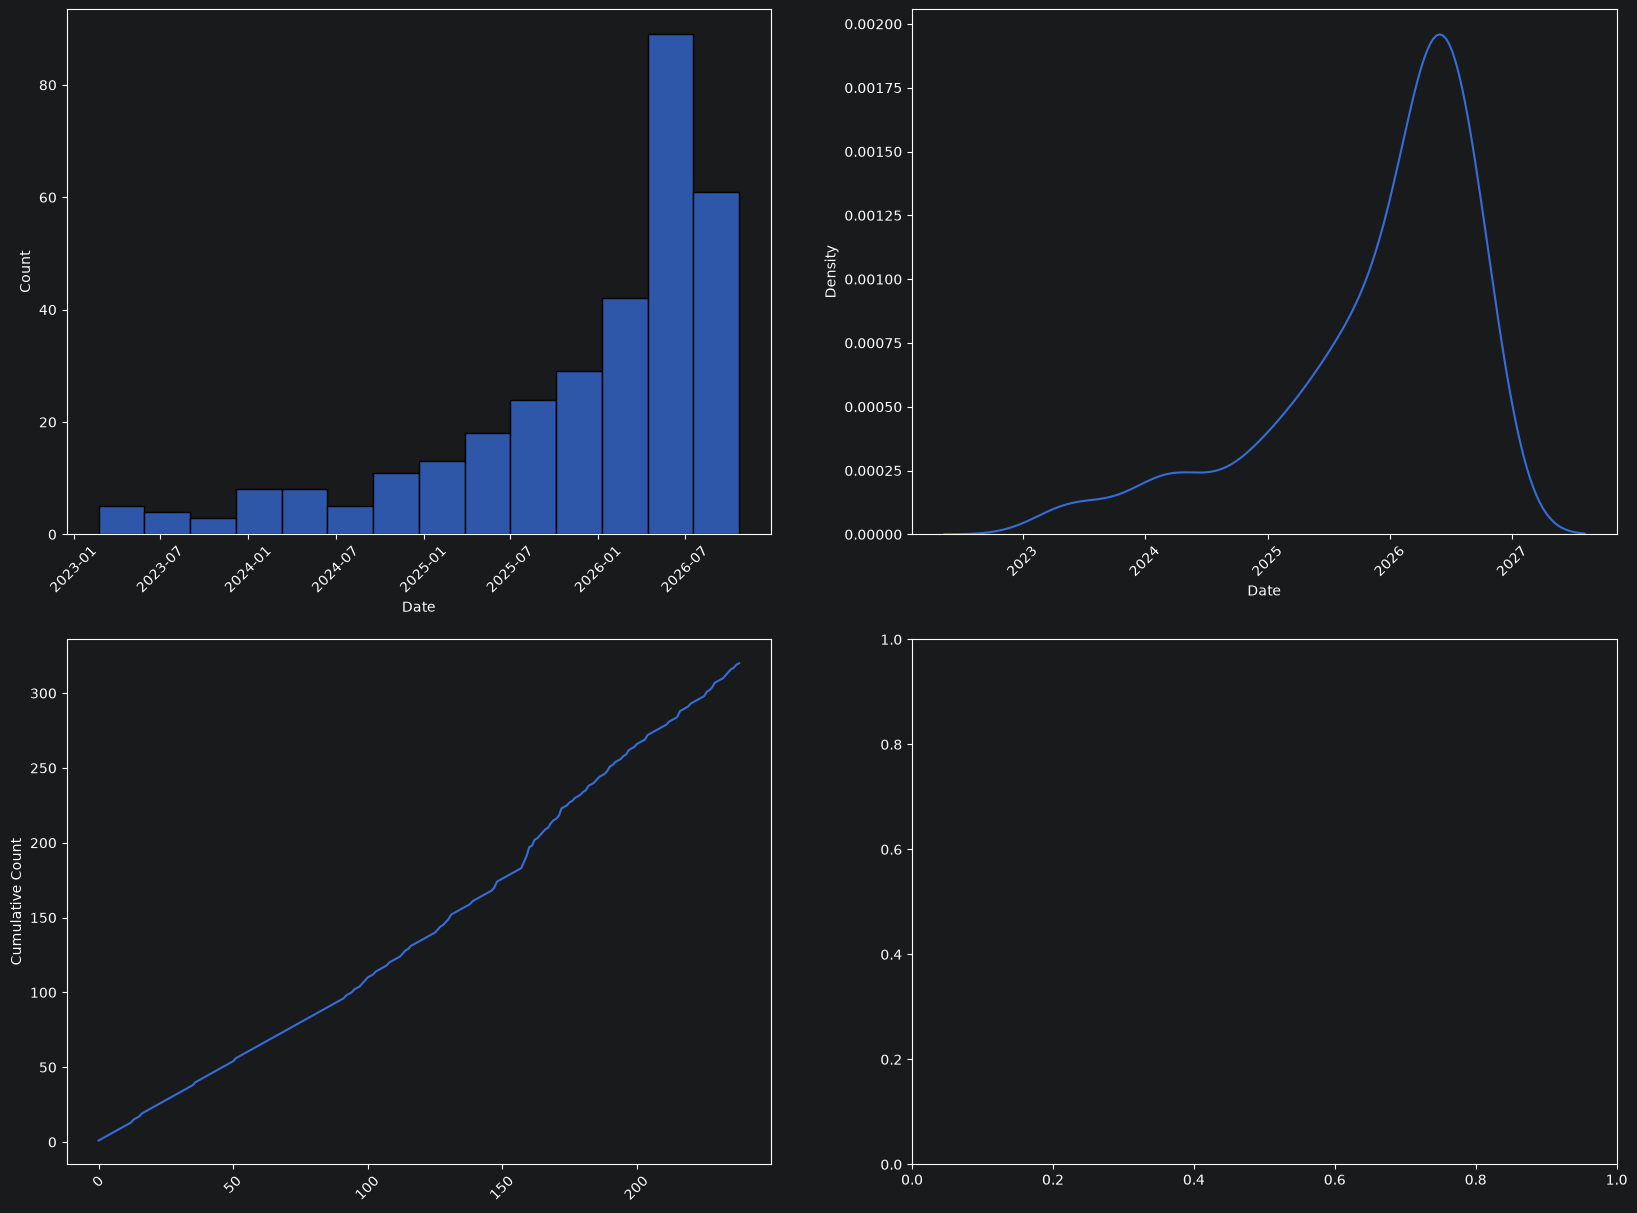

In [22]:
layoff_events_distribution(df_5)

**Which companies have reported the highest number of layoffs?**

In [23]:
def highest_layoffs(df_5,**kwargs):
    df_e = df_5.copy()
    for i in kwargs:
        df_e = df_e[df_e[i].isin(kwargs[i])]
    df_highest_layoffs = df_e.groupby("Company")["Roles counted"].sum().sort_values(ascending=False).reset_index()
    companies_with_highest_layoffs = df_highest_layoffs[df_highest_layoffs["Roles counted"]>=4000]["Company"].values.tolist()
    return companies_with_highest_layoffs

highest_layoffs(df_5)

['Meta',
 'Cisco',
 'British American Tobacco',
 'Teleperformance',
 'Barclays',
 'Dow Inc.',
 'Block (Square)',
 'HP Inc.']

**2. Industry analysis**

**Which industries have experienced the highest layoff activity?**

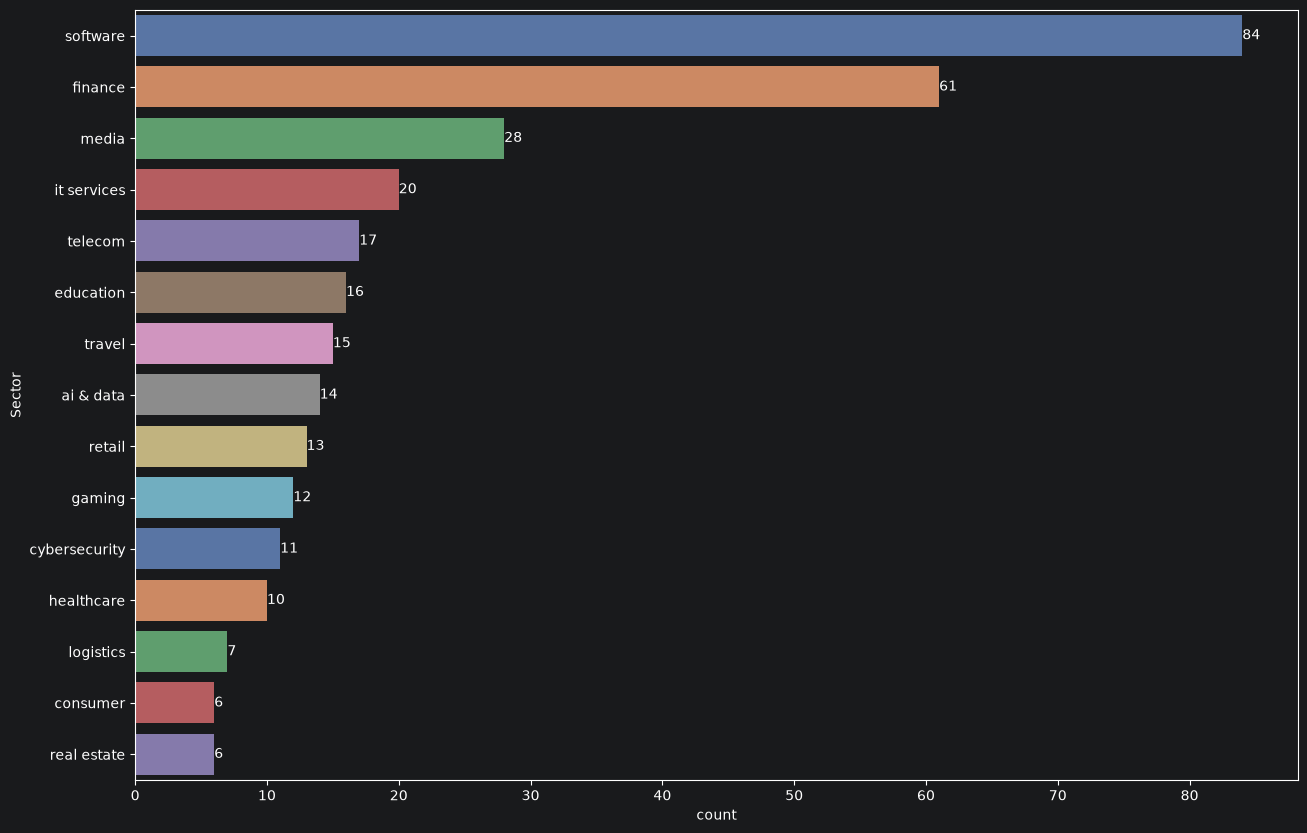

In [34]:
fig, ax = plt.subplots(figsize=(15,10))
sns.barplot(df_5["Sector"].value_counts(),orient="h",ax=ax,palette="deep")
for i in ax.containers:
    ax.bar_label(i)

**Which industries account for the largest number of affected employees?**